# Deep Learning – Assignment 4: Sequential Modeling with Recurrent Networks
**Group 3**

# Task 1: Sequential Handwritten Digit Classification (Kannada MNIST, row-by-row)

In [6]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

os.makedirs("results", exist_ok=True)


TensorFlow version: 2.21.0
GPU available: []


In [7]:


import os
import pandas as pd

# Read the dataset already uploaded to Google Colab
filename = "/content/Dig-MNIST.csv (1).zip"

if not os.path.exists(filename):
    raise FileNotFoundError(
        f"Could not find {filename}. "
        "Check the filename in the Colab Files panel."
    )

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns[:10].tolist())
display(df.head())


Dataset loaded successfully!
Dataset shape: (10240, 785)
Column names: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8']


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:

# Extract labels
if "label" not in df.columns:
    raise ValueError(
        "The CSV must contain a 'label' column. "
        "Upload the labelled train.csv file, not test.csv."
    )

y = df["label"].to_numpy().astype("int64")

# Extract the 784 pixel columns, ignoring any optional ID column
pixel_cols = [
    col for col in df.columns
    if col != "label" and (
        str(col).lower().startswith("pixel")
        or str(col).isdigit()
    )
]

if len(pixel_cols) != 784:
    # Fallback: select all numeric columns except label and common IDs
    excluded = {"label", "id", "imageid"}
    pixel_cols = [
        col for col in df.columns
        if str(col).lower() not in excluded
        and pd.api.types.is_numeric_dtype(df[col])
    ]

    # If an ID column is present, remove it
    if len(pixel_cols) == 785:
        pixel_cols = [
            col for col in pixel_cols
            if str(col).lower() not in {"id", "imageid"}
        ]

if len(pixel_cols) != 784:
    raise ValueError(
        f"Expected 784 pixel columns but found {len(pixel_cols)}. "
        "Check the CSV format."
    )

X_images = df[pixel_cols].to_numpy(dtype="float32")
X_images = X_images.reshape(-1, 28, 28) / 255.0

# Required sequential representation:
# samples x time steps x features = N x 28 x 28
X = X_images.copy()

num_classes = len(np.unique(y))

print("Sequential input shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))
print("Number of classes:", num_classes)

assert X.shape[1:] == (28, 28)
assert num_classes == 10, "Expected all 10 digit classes."


Sequential input shape: (10240, 28, 28)
Labels shape: (10240,)
Classes: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10


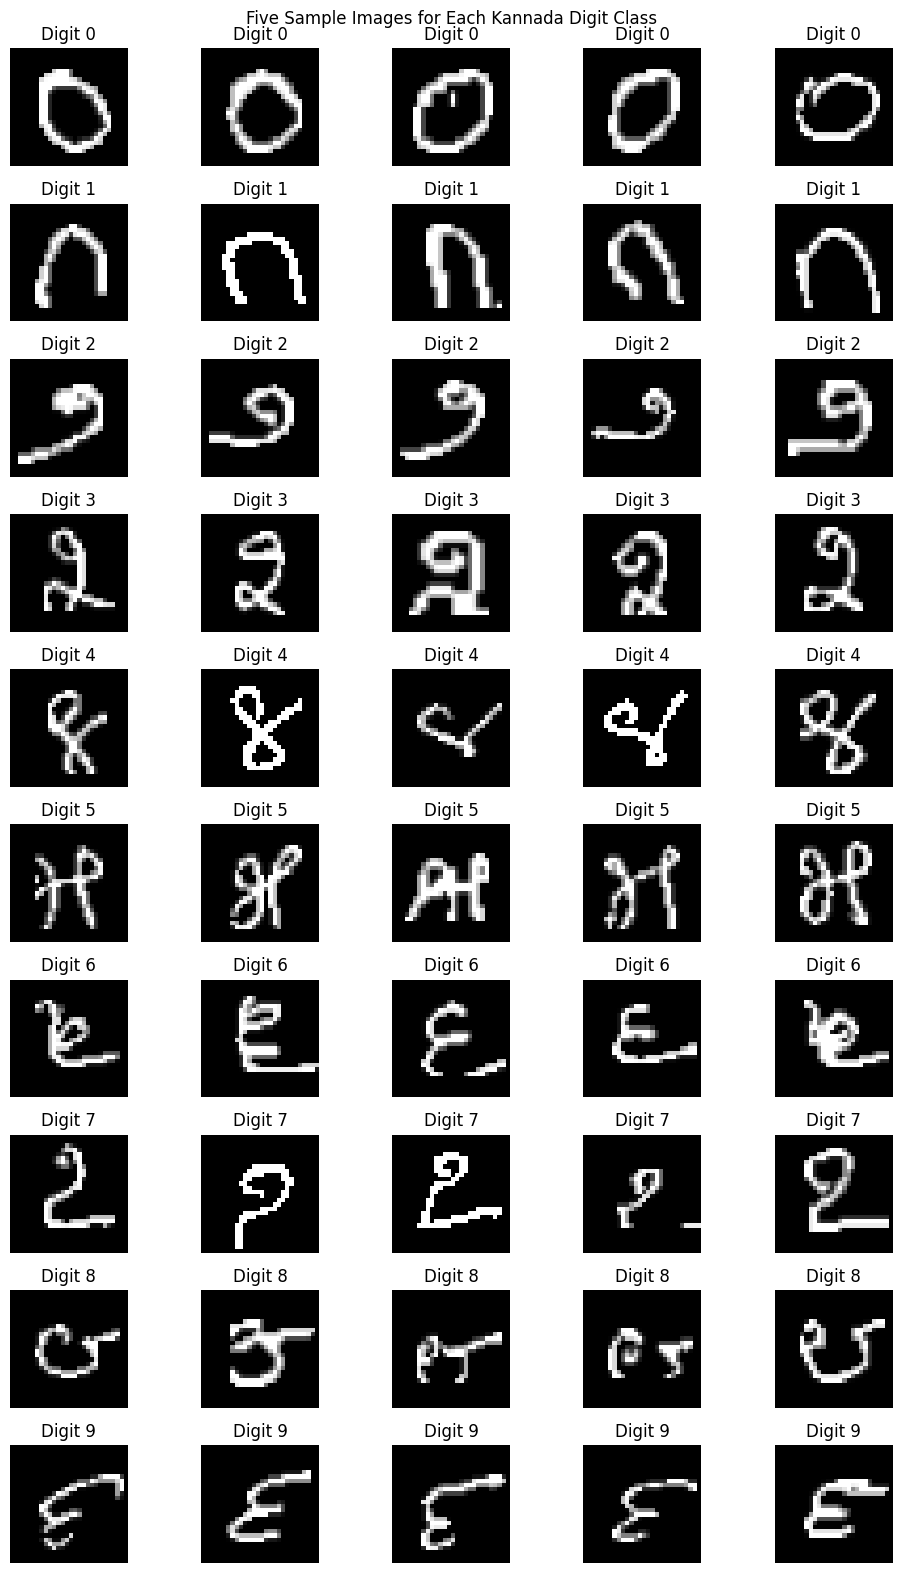

In [9]:

fig, axes = plt.subplots(10, 5, figsize=(10, 16))

for digit in range(10):
    indices = np.where(y == digit)[0][:5]

    for j in range(5):
        ax = axes[digit, j]

        if j < len(indices):
            ax.imshow(X_images[indices[j]], cmap="gray")
            ax.set_title(f"Digit {digit}")
        ax.axis("off")

plt.suptitle("Five Sample Images for Each Kannada Digit Class")
plt.tight_layout()
plt.savefig("results/digit_samples.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nInput shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training samples: 7168
Validation samples: 1536
Test samples: 1536

Input shapes:
Training: (7168, 28, 28)
Validation: (1536, 28, 28)
Test: (1536, 28, 28)


In [11]:

CONFIGS = [
    {
        "name": "RNN_64_lr001",
        "model": "RNN",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "RNN_128_lr001",
        "model": "RNN",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_64_lr001",
        "model": "LSTM",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_128_lr0005",
        "model": "LSTM",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    },
    {
        "name": "GRU_64_lr001",
        "model": "GRU",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "GRU_128_lr0005",
        "model": "GRU",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    }
]

EPOCHS = 20
BATCH_SIZE = 128

def build_model(config):
    model = Sequential()
    model.add(tf.keras.Input(shape=(28, 28)))

    layer_type = {
        "RNN": SimpleRNN,
        "LSTM": LSTM,
        "GRU": GRU
    }[config["model"]]

    model.add(
        layer_type(
            config["units"],
            dropout=config["dropout"]
        )
    )
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Total configurations:", len(CONFIGS))


Total configurations: 6


In [12]:

histories = {}
models = {}
results = []

for config in CONFIGS:
    print("\n" + "=" * 65)
    print("Training:", config["name"])
    print("=" * 65)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(config)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluate restored best-validation-loss weights
    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        X_val, y_val, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[config["name"]] = history.history
    models[config["name"]] = model

    results.append({
        "Configuration": config["name"],
        "Architecture": config["model"],
        "Units": config["units"],
        "Dropout": config["dropout"],
        "Learning Rate": config["learning_rate"],
        "Epochs Trained": len(history.history["loss"]),
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Training Loss": train_loss,
        "Test Loss": test_loss
    })

    print(f"Training accuracy:   {train_acc:.4f}")
    print(f"Validation accuracy:  {val_acc:.4f}")
    print(f"Test accuracy:       {test_acc:.4f}")

results_df = pd.DataFrame(results)
results_df.to_csv("results/hyperparameter_results.csv", index=False)

print("\nAll experiments completed.")



Training: RNN_64_lr001
Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4314 - loss: 1.7888 - val_accuracy: 0.6042 - val_loss: 1.2265
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6844 - loss: 0.9909 - val_accuracy: 0.7142 - val_loss: 0.8705
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7561 - loss: 0.7687 - val_accuracy: 0.7526 - val_loss: 0.7581
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7893 - loss: 0.6742 - val_accuracy: 0.7891 - val_loss: 0.6807
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8115 - loss: 0.6076 - val_accuracy: 0.8008 - val_loss: 0.6530
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8290 - loss: 0.5621 - val_accuracy: 0.8079 - val_loss: 0.6362
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8436 - loss: 0.5188 - val_accuracy: 0.8112 - val_loss: 0.6176
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8514 - loss: 0.4877 - val_acc

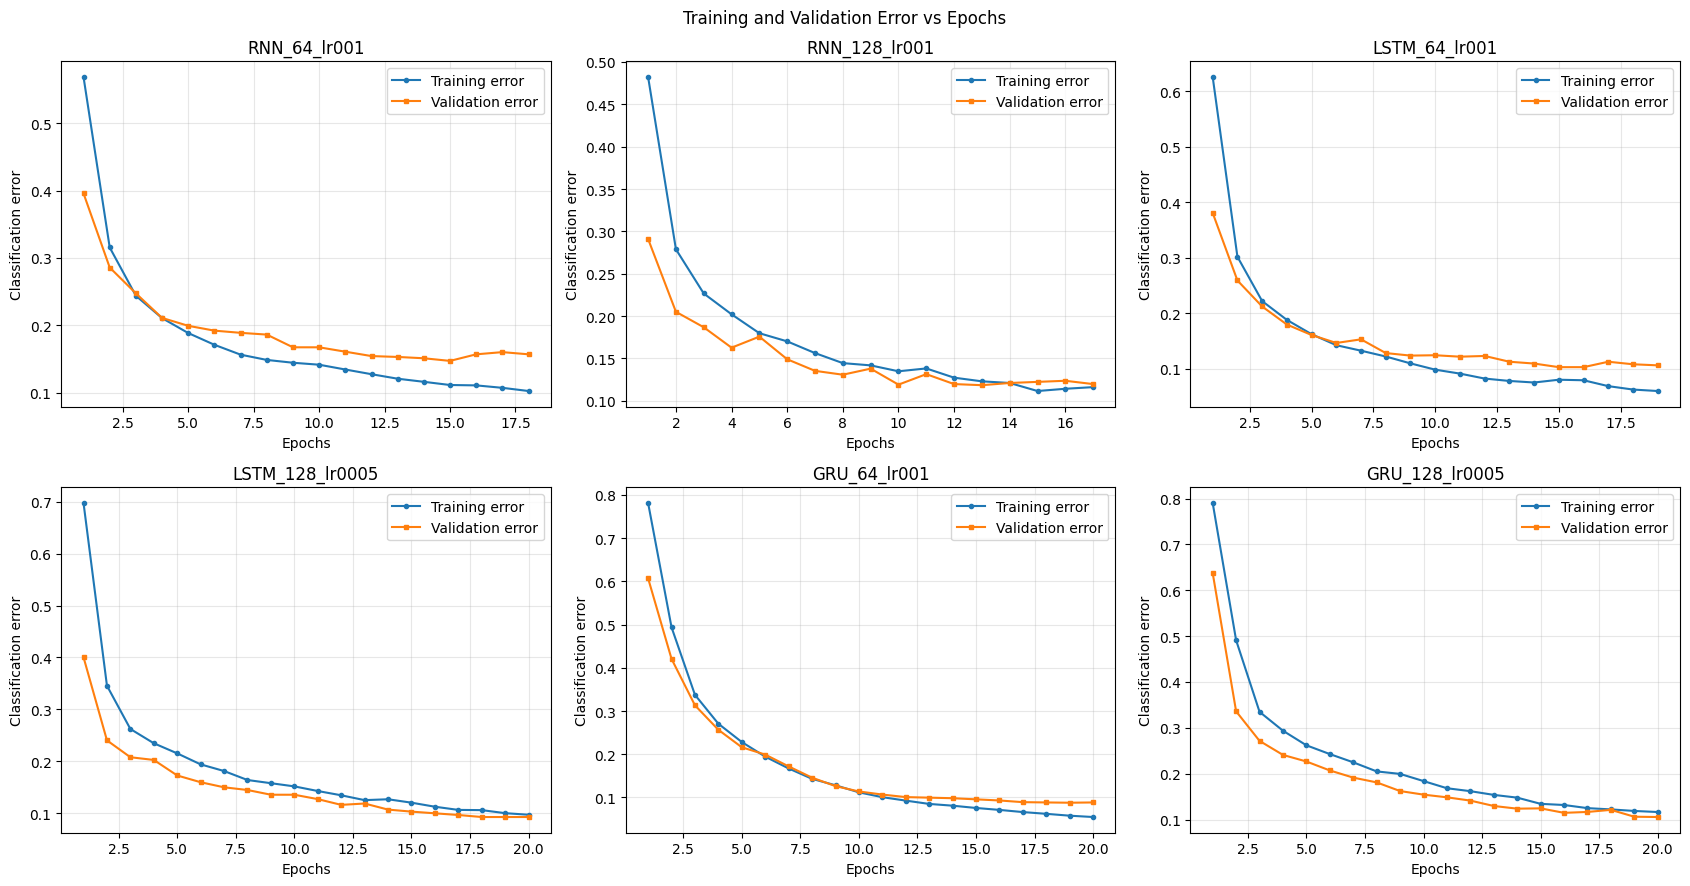

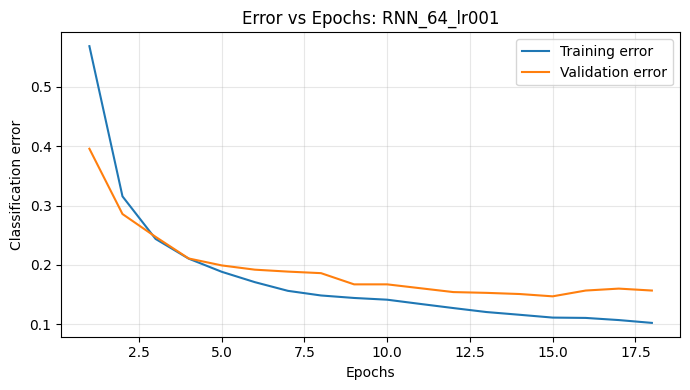

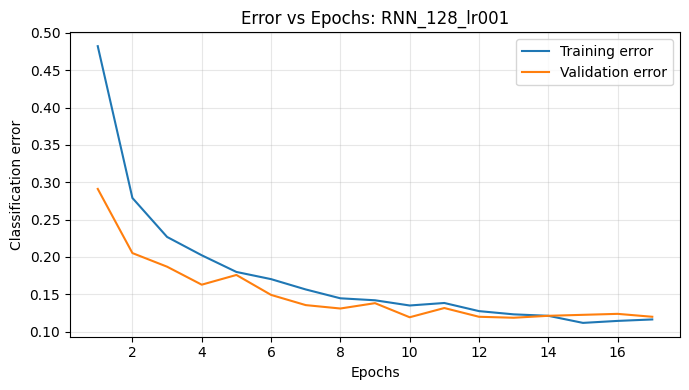

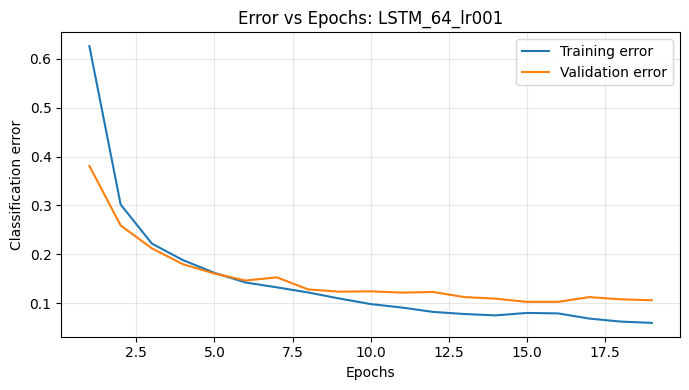

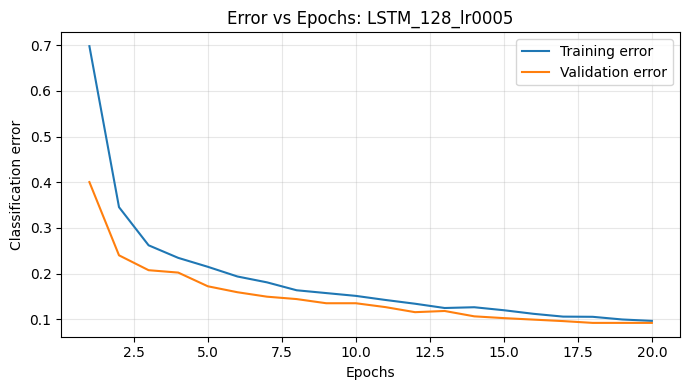

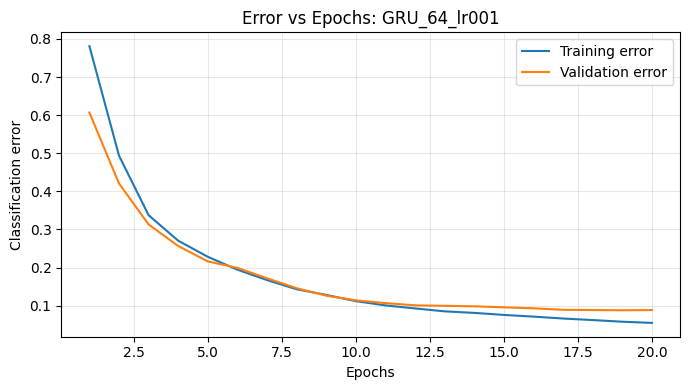

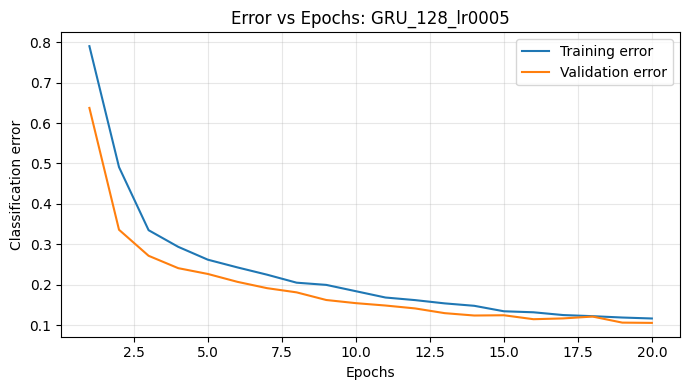

In [13]:

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for ax, config in zip(axes, CONFIGS):
    h = histories[config["name"]]

    train_error = 1 - np.array(h["accuracy"])
    val_error = 1 - np.array(h["val_accuracy"])

    epochs = np.arange(1, len(train_error) + 1)

    ax.plot(epochs, train_error, marker="o",
            markersize=3, label="Training error")
    ax.plot(epochs, val_error, marker="s",
            markersize=3, label="Validation error")

    ax.set_title(config["name"])
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Classification error")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Training and Validation Error vs Epochs")
plt.tight_layout()
plt.savefig("results/all_training_error_plots.png",
            dpi=200, bbox_inches="tight")
plt.show()

# Save an individual error plot for every configuration
for config in CONFIGS:
    h = histories[config["name"]]
    epochs = np.arange(1, len(h["accuracy"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, 1 - np.array(h["accuracy"]),
             label="Training error")
    plt.plot(epochs, 1 - np.array(h["val_accuracy"]),
             label="Validation error")

    plt.title(f"Error vs Epochs: {config['name']}")
    plt.xlabel("Epochs")
    plt.ylabel("Classification error")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"results/error_{config['name']}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close()


In [14]:

display_df = results_df[
    [
        "Configuration",
        "Architecture",
        "Units",
        "Dropout",
        "Learning Rate",
        "Epochs Trained",
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy"
    ]
].copy()

for col in [
    "Training Accuracy",
    "Validation Accuracy",
    "Test Accuracy"
]:
    display_df[col] = (100 * display_df[col]).round(2)

print("Accuracy comparison (percent):")
display(display_df)

display_df.to_csv(
    "results/accuracy_summary.csv",
    index=False
)


Accuracy comparison (percent):


,Configuration,Architecture,Units,Dropout,Learning Rate,Epochs Trained,Training Accuracy,Validation Accuracy,Test Accuracy
0,RNN_64_lr001,RNN,64,0.0,0.0010,18,88.85,84.90,85.48
1,RNN_128_lr001,RNN,128,0.2,0.0010,17,90.85,88.15,89.00
2,LSTM_64_lr001,LSTM,64,0.0,0.0010,19,93.44,89.71,90.30
3,LSTM_128_lr0005,LSTM,128,0.2,0.0005,20,93.09,90.76,89.91
4,GRU_64_lr001,GRU,64,0.0,0.0010,20,94.36,91.15,89.58
5,GRU_128_lr0005,GRU,128,0.2,0.0005,20,91.00,89.45,88.61


In [15]:

best_row = results_df.loc[
    results_df["Validation Accuracy"].idxmax()
]

best_name = best_row["Configuration"]
best_model = models[best_name]

print("Best configuration:", best_name)
print("Architecture:", best_row["Architecture"])
print("Hidden units:", best_row["Units"])
print("Dropout:", best_row["Dropout"])
print("Learning rate:", best_row["Learning Rate"])
print(f"Training accuracy: {100*best_row['Training Accuracy']:.2f}%")
print(f"Validation accuracy: {100*best_row['Validation Accuracy']:.2f}%")
print(f"Test accuracy: {100*best_row['Test Accuracy']:.2f}%")


Best configuration: GRU_64_lr001
Architecture: GRU
Hidden units: 64
Dropout: 0.0
Learning rate: 0.001
Training accuracy: 94.36%
Validation accuracy: 91.15%
Test accuracy: 89.58%


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
Best model: GRU_64_lr001
Final test accuracy: 89.58%

Classification report:
              precision    recall  f1-score   support

           0     0.8616    0.8954    0.8782       153
           1     0.8917    0.9150    0.9032       153
           2     0.9178    0.8701    0.8933       154
           3     0.9272    0.9091    0.9180       154
           4     0.8924    0.9156    0.9038       154
           5     0.9080    0.9610    0.9338       154
           6     0.8889    0.7792    0.8304       154
           7     0.8537    0.9150    0.8833       153
           8     0.8598    0.9156    0.8868       154
           9     0.9712    0.8824    0.9247       153

    accuracy                         0.8958      1536
   macro avg     0.8972    0.8958    0.8956      1536
weighted avg     0.8972    0.8958    0.8956      1536



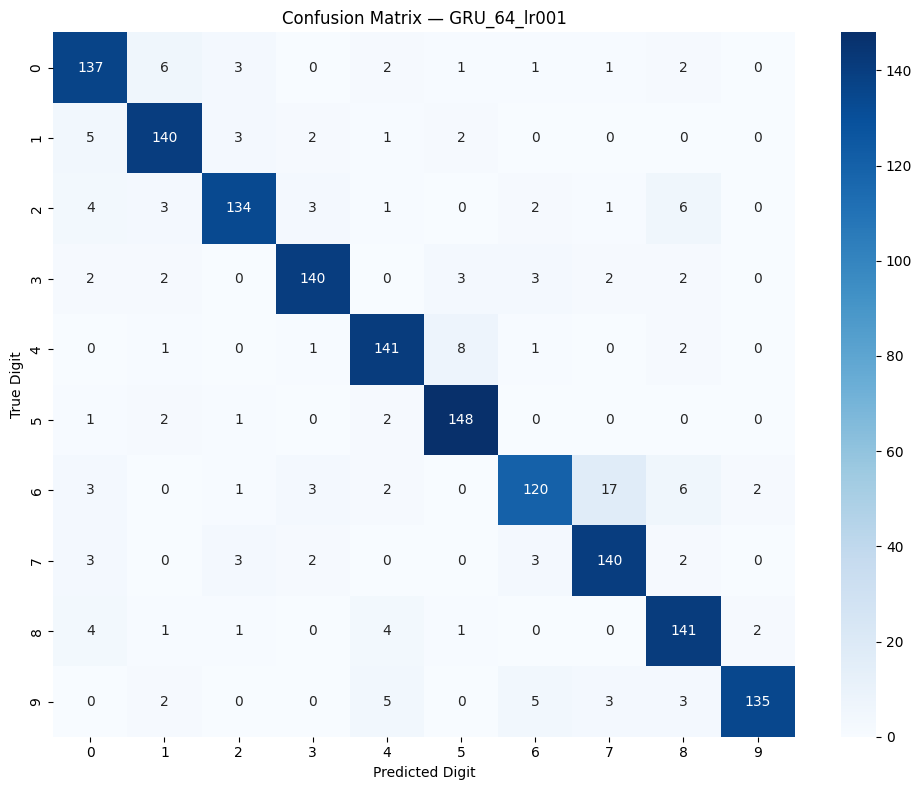

In [16]:

y_prob = best_model.predict(
    X_test, batch_size=BATCH_SIZE, verbose=1
)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

print(f"Best model: {best_name}")
print(f"Final test accuracy: {100*test_accuracy:.2f}%")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        digits=4,
        zero_division=0
    )
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.savefig("results/best_confusion_matrix.png",
            dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(
    cm,
    index=[f"True {i}" for i in range(10)],
    columns=[f"Predicted {i}" for i in range(10)]
).to_csv("results/confusion_matrix.csv")


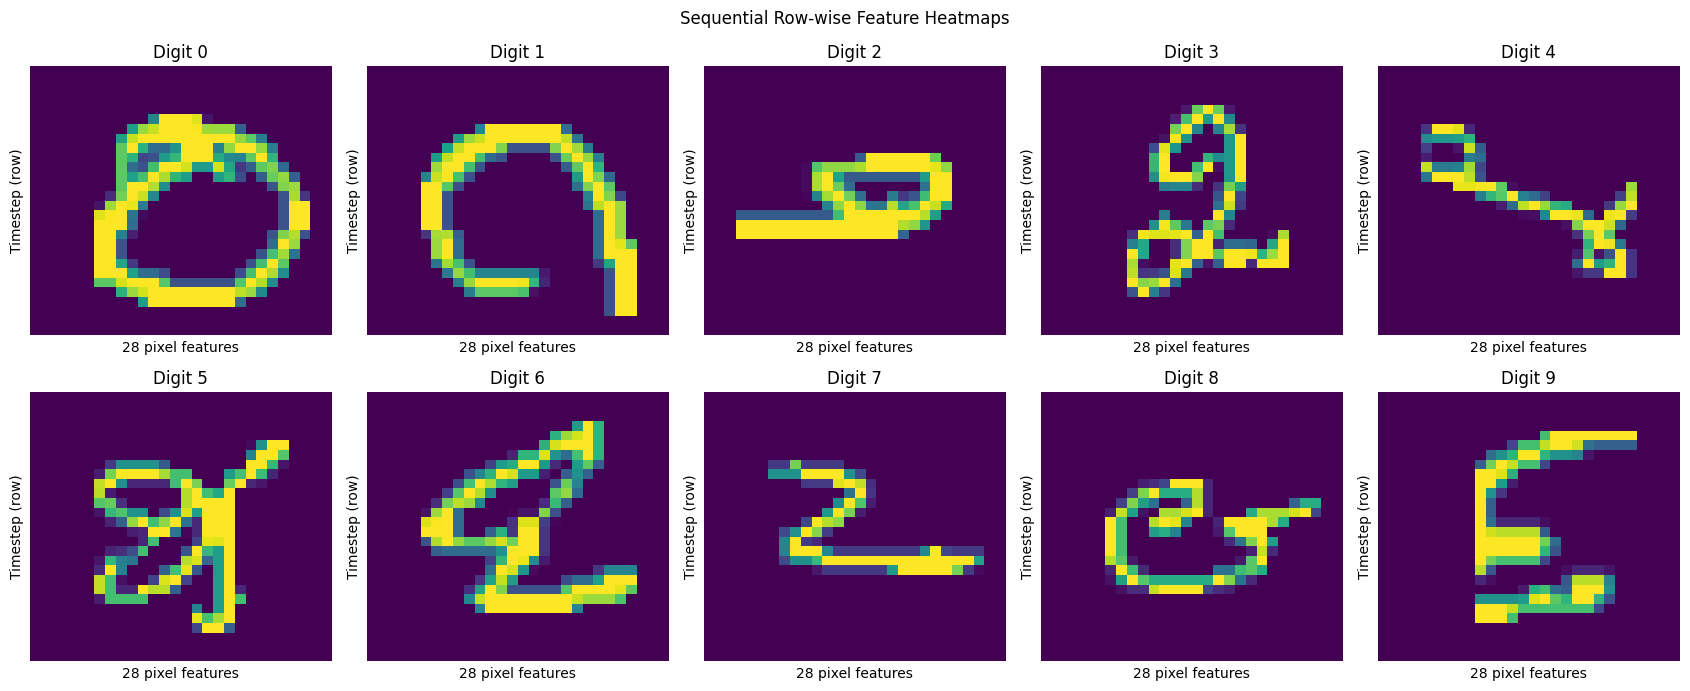

In [17]:

# Choose one test image from each digit class
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]

    # Each row is one timestep; each column is one pixel feature
    sequence = X_test[idx]

    sns.heatmap(
        sequence,
        ax=axes[digit],
        cmap="viridis",
        cbar=False,
        xticklabels=False,
        yticklabels=False
    )

    axes[digit].set_title(f"Digit {digit}")
    axes[digit].set_xlabel("28 pixel features")
    axes[digit].set_ylabel("Timestep (row)")

plt.suptitle("Sequential Row-wise Feature Heatmaps")
plt.tight_layout()
plt.savefig("results/sequential_feature_heatmaps.png",
            dpi=200, bbox_inches="tight")
plt.show()


  Architecture  Best_Validation_Accuracy  Best_Test_Accuracy
0          GRU                  0.911458            0.895833
1         LSTM                  0.907552            0.902995
2          RNN                  0.881510            0.889974


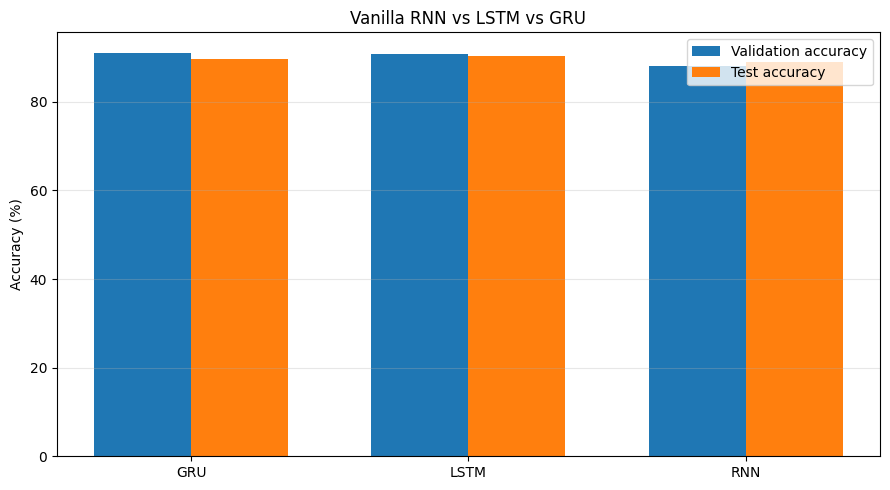

In [18]:

architecture_summary = (
    results_df.groupby("Architecture", as_index=False)
    .agg(
        Best_Validation_Accuracy=("Validation Accuracy", "max"),
        Best_Test_Accuracy=("Test Accuracy", "max")
    )
)

print(architecture_summary)

x = np.arange(len(architecture_summary))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    x - width/2,
    architecture_summary["Best_Validation_Accuracy"] * 100,
    width,
    label="Validation accuracy"
)
plt.bar(
    x + width/2,
    architecture_summary["Best_Test_Accuracy"] * 100,
    width,
    label="Test accuracy"
)

plt.xticks(x, architecture_summary["Architecture"])
plt.ylabel("Accuracy (%)")
plt.title("Vanilla RNN vs LSTM vs GRU")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/architecture_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()


In [21]:

import shutil

# Save the best model
best_model.save("results/best_model.keras")

# Save the complete experiment summary
results_df.to_csv("results/all_experiment_results.csv", index=False)

# Package figures, tables, confusion matrix, and best model
shutil.make_archive("Task1_Report_Results", "zip", "results")

files.download("Task1_Report_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 2: Spoken Digit Sequential Classification (Arabic Digit MFCC sequences)

In [1]:
import os, random, time, glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Locate the two files (works for nested folders too)
TRAIN_PATH = glob.glob("**/Train_Arabic_Digit.txt", recursive=True)[0]
TEST_PATH  = glob.glob("**/Test_Arabic_Digit.txt",  recursive=True)[0]
print(TRAIN_PATH, TEST_PATH)

SEED       = 42
BATCH_SIZE = 64
LR         = 1e-3
CLIP       = 5.0        # gradient clipping (important for vanilla RNN)
TOL        = 1e-4       # convergence threshold |L(k) - L(k-1)| < TOL
MIN_EPOCHS = 5          # safety: don't stop in the first noisy epochs
MAX_EPOCHS = 100        # safety cap
DROPOUT    = 0.2        # between layers, only when layers > 1

CELLS   = ["RNN", "LSTM", "GRU"]
LAYERS  = [1, 2]
HIDDENS = [32, 64, 128]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

set_seed()

Train_Arabic_Digit.txt Test_Arabic_Digit.txt
Device: cpu


In [2]:
def load_arabic_digits(path):
    seqs, cur = [], []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                cur.append([float(v) for v in line.split()])
            elif cur:
                seqs.append(np.asarray(cur, dtype=np.float32))
                cur = []
    if cur:
        seqs.append(np.asarray(cur, dtype=np.float32))
    per_class = len(seqs) // 10
    labels = np.repeat(np.arange(10), per_class)
    assert len(seqs) == len(labels), f"Unexpected number of utterances: {len(seqs)}"
    return seqs, labels

X_all, y_all = load_arabic_digits(TRAIN_PATH)
X_test, y_test = load_arabic_digits(TEST_PATH)
lens_all = np.array([len(x) for x in X_all])
print(f"Train utterances: {len(X_all)} | Test utterances: {len(X_test)}")
print(f"Sequence length: min={lens_all.min()}, max={lens_all.max()}, mean={lens_all.mean():.1f}")
print("Train class counts:", np.bincount(y_all))
print("Test  class counts:", np.bincount(y_test))

# Train / validation split (stratified 90/10); test stays held out
idx = np.arange(len(X_all))
tr_idx, va_idx = train_test_split(idx, test_size=0.1, stratify=y_all, random_state=SEED)
X_train = [X_all[i] for i in tr_idx]; y_train = y_all[tr_idx]
X_val   = [X_all[i] for i in va_idx]; y_val   = y_all[va_idx]
print(f"Split -> train {len(X_train)}, val {len(X_val)}, test {len(X_test)}")

# Standardise each MFCC coefficient using TRAIN statistics only
frames = np.concatenate(X_train, axis=0)
mu, sd = frames.mean(0), frames.std(0) + 1e-8
norm = lambda L: [torch.from_numpy((x - mu) / sd) for x in L]
Xtr_t, Xva_t, Xte_t = norm(X_train), norm(X_val), norm(X_test)

Train utterances: 6600 | Test utterances: 2200
Sequence length: min=4, max=93, mean=39.9
Train class counts: [660 660 660 660 660 660 660 660 660 660]
Test  class counts: [220 220 220 220 220 220 220 220 220 220]
Split -> train 5940, val 660, test 2200


In [3]:
class SeqDS(Dataset):
    def __init__(self, xs, ys): self.xs, self.ys = xs, ys
    def __len__(self): return len(self.xs)
    def __getitem__(self, i): return self.xs[i], int(self.ys[i])

def collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs])            # stays on CPU (needed by packing)
    xpad = pad_sequence(xs, batch_first=True)               # (B, Tmax, 13)
    return xpad, lengths, torch.tensor(ys)

def loader(xs, ys, bs, shuffle):
    return DataLoader(SeqDS(xs, ys), batch_size=bs, shuffle=shuffle, collate_fn=collate)

train_loader = loader(Xtr_t, y_train, BATCH_SIZE, True)
train_eval   = loader(Xtr_t, y_train, 256, False)
val_loader   = loader(Xva_t, y_val, 256, False)
test_loader  = loader(Xte_t, y_test, 256, False)

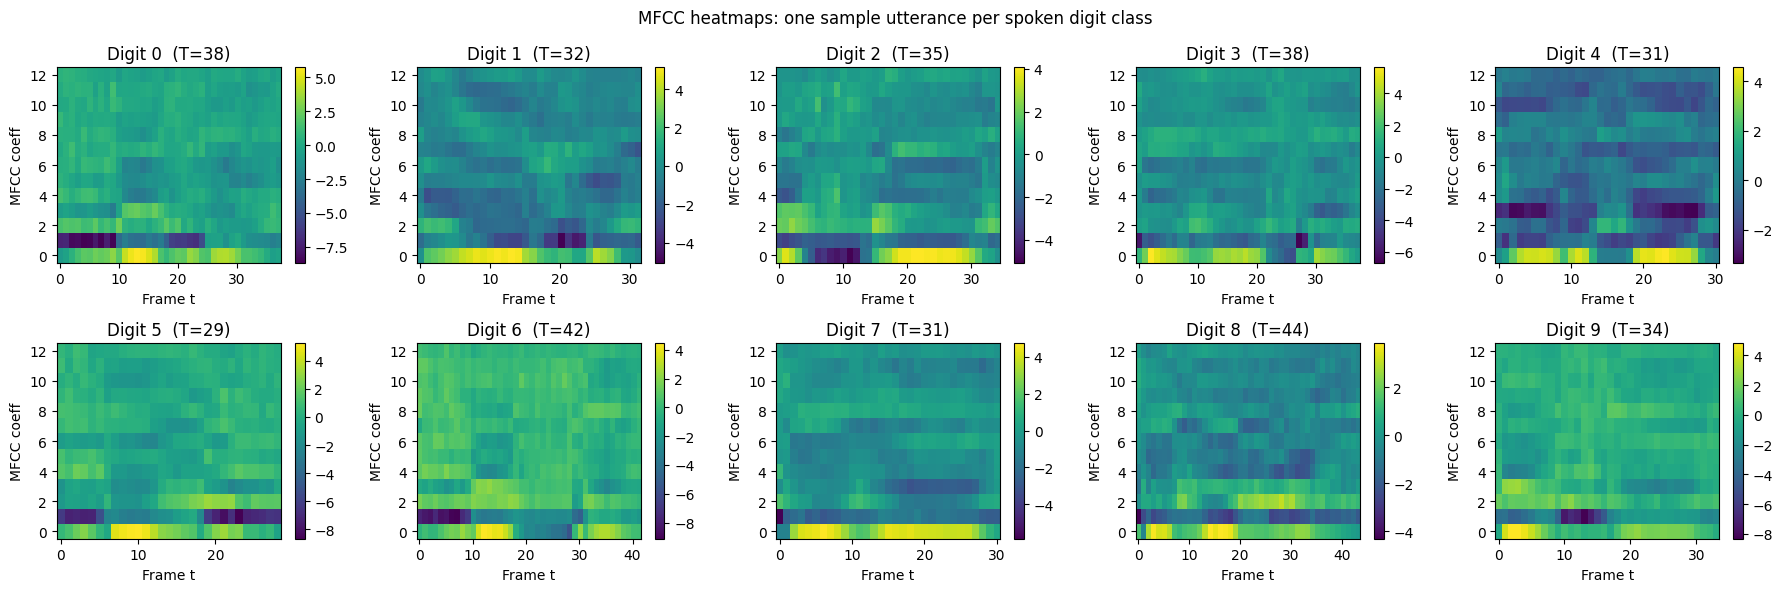

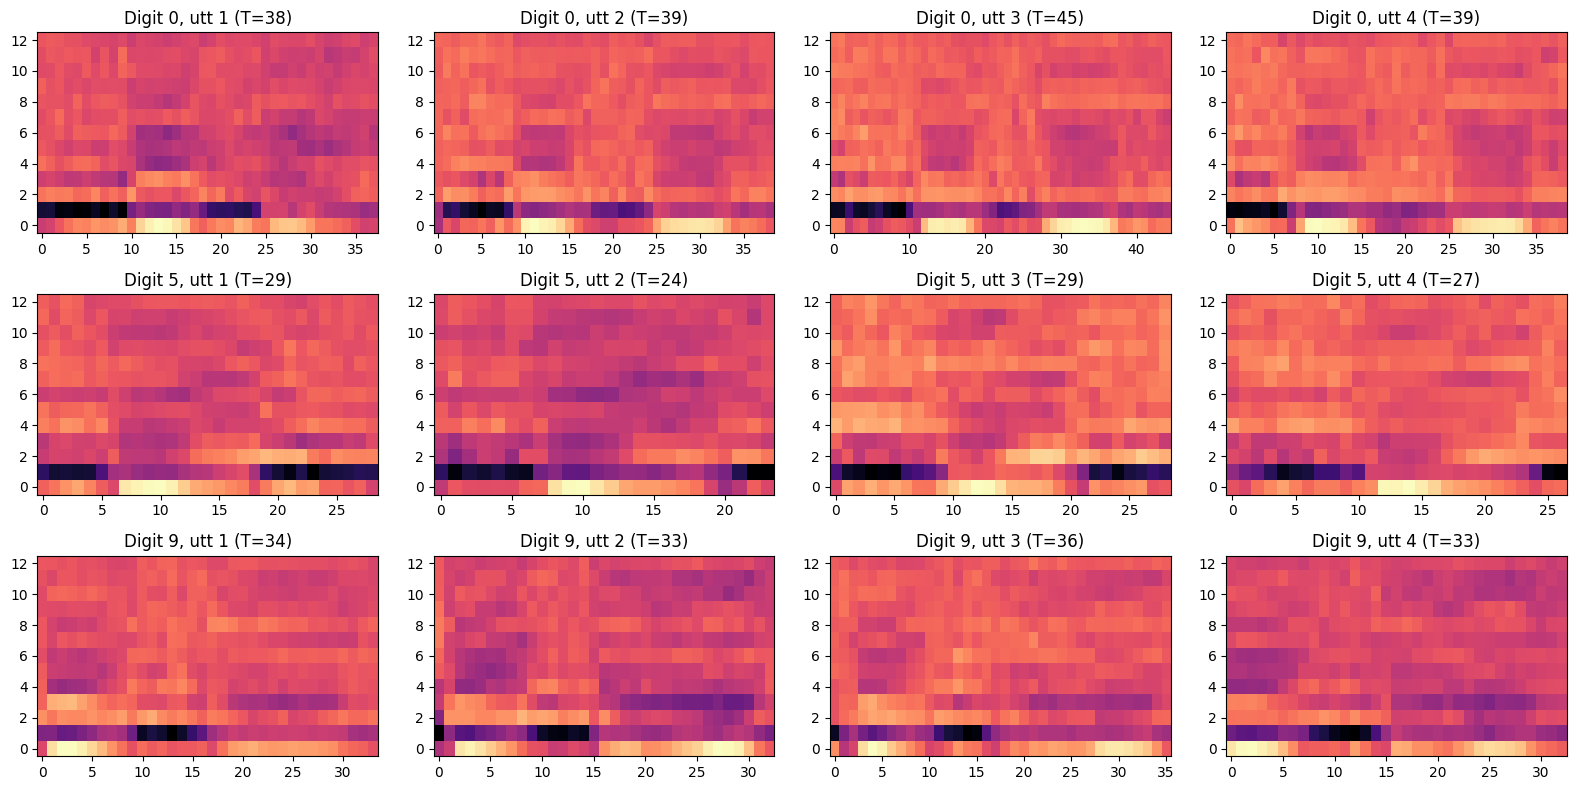

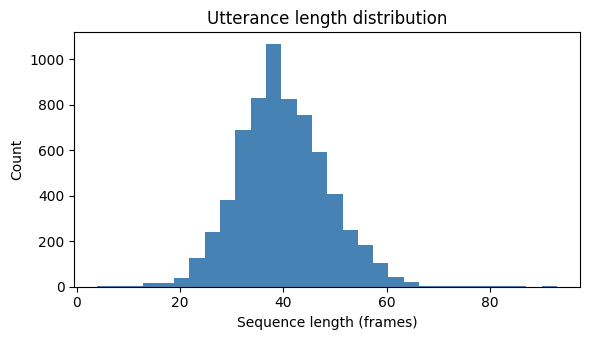

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for d in range(10):
    i = int(np.where(y_all == d)[0][0])
    ax = axes[d // 5, d % 5]
    im = ax.imshow(X_all[i].T, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"Digit {d}  (T={len(X_all[i])})")
    ax.set_xlabel("Frame t"); ax.set_ylabel("MFCC coeff")
    fig.colorbar(im, ax=ax)
plt.suptitle("MFCC heatmaps: one sample utterance per spoken digit class")
plt.tight_layout(); plt.savefig("task2_mfcc_heatmaps.png", dpi=150); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 8))
for r, d in enumerate([0, 5, 9]):
    ids = np.where(y_all == d)[0][:4]
    for c, i in enumerate(ids):
        axes[r, c].imshow(X_all[i].T, aspect="auto", origin="lower", cmap="magma")
        axes[r, c].set_title(f"Digit {d}, utt {c+1} (T={len(X_all[i])})")
plt.tight_layout(); plt.savefig("task2_mfcc_variability.png", dpi=150); plt.show()

plt.figure(figsize=(6, 3.5))
plt.hist(lens_all, bins=30, color="steelblue")
plt.xlabel("Sequence length (frames)"); plt.ylabel("Count"); plt.title("Utterance length distribution")
plt.tight_layout(); plt.show()

In [5]:
class SeqClassifier(nn.Module):
    def __init__(self, cell="LSTM", hidden=64, layers=1, bidir=False, attn=False,
                 in_dim=13, n_cls=10, dropout=DROPOUT):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        extra = {"nonlinearity": "tanh"} if cell == "RNN" else {}
        self.rnn = rnn_cls(in_dim, hidden, layers, batch_first=True, bidirectional=bidir,
                           dropout=dropout if layers > 1 else 0.0, **extra)
        d = hidden * (2 if bidir else 1)
        self.cell, self.bidir, self.attn = cell, bidir, attn
        if attn:
            self.att = nn.Linear(d, 1)
        self.fc = nn.Linear(d, n_cls)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        if self.attn:                                        # masked temporal attention pooling
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
            mask = torch.arange(x.size(1), device=x.device)[None, :] < lengths.to(x.device)[:, None]
            score = self.att(out).squeeze(-1).masked_fill(~mask, -1e9)
            w = torch.softmax(score, dim=1)
            feat = (w.unsqueeze(-1) * out).sum(1)
        else:                                                # last hidden state of top layer
            if self.cell == "LSTM":
                h = h[0]
            feat = torch.cat([h[-2], h[-1]], 1) if self.bidir else h[-1]
        return self.fc(feat)

In [6]:
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    P, Y = [], []
    for x, l, y in dl:
        P.append(model(x.to(DEVICE), l).argmax(1).cpu()); Y.append(y)
    p, t = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return (p == t).mean(), p, t

def train_model(cfg, verbose=False):
    set_seed()
    model = SeqClassifier(**cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    losses, gnorms, converged = [], [], False
    t0 = time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train()
        tot, n, gsum, nb = 0.0, 0, 0.0, 0
        for x, l, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(x, l), y)
            loss.backward()
            gn = nn.utils.clip_grad_norm_(model.parameters(), CLIP)   # pre-clip norm
            opt.step()
            tot += loss.item() * len(y); n += len(y); gsum += float(gn); nb += 1
        losses.append(tot / n); gnorms.append(gsum / nb)
        if verbose:
            print(f"  epoch {ep:3d}  loss {losses[-1]:.5f}  grad-norm {gnorms[-1]:.3f}")
        if ep >= MIN_EPOCHS and abs(losses[-1] - losses[-2]) < TOL:
            converged = True
            break
    tr_acc, _, _ = evaluate(model, train_eval)
    va_acc, _, _ = evaluate(model, val_loader)
    te_acc, _, _ = evaluate(model, test_loader)
    return dict(cfg=cfg, model=model, losses=losses, gnorms=gnorms, epochs=len(losses),
                converged=converged, train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
                time=time.time() - t0)

def cfg_name(c):
    s = f"{c['cell']} L{c['layers']} H{c['hidden']}"
    if c.get("bidir"): s += " Bi"
    if c.get("attn"):  s += " Attn"
    return s

In [7]:
results = []
for cell in CELLS:
    for L in LAYERS:
        for H in HIDDENS:
            cfg = dict(cell=cell, layers=L, hidden=H, bidir=False, attn=False)
            r = train_model(cfg)
            results.append(r)
            print(f"{cfg_name(cfg):16s} epochs={r['epochs']:3d} conv={r['converged']!s:5s} "
                  f"train={r['train_acc']:.4f} val={r['val_acc']:.4f} test={r['test_acc']:.4f} "
                  f"({r['time']:.0f}s)")

RNN L1 H32       epochs=100 conv=False train=0.9606 val=0.9242 test=0.8536 (194s)
RNN L1 H64       epochs=100 conv=False train=0.9815 val=0.9530 test=0.8909 (190s)
RNN L1 H128      epochs=100 conv=False train=0.9948 val=0.9848 test=0.9464 (302s)
RNN L2 H32       epochs=100 conv=False train=0.9837 val=0.9667 test=0.9036 (256s)
RNN L2 H64       epochs= 47 conv=True  train=0.9732 val=0.9591 test=0.9305 (179s)
RNN L2 H128      epochs=100 conv=False train=0.9884 val=0.9697 test=0.9332 (691s)
LSTM L1 H32      epochs= 33 conv=True  train=0.9966 val=0.9803 test=0.9432 (124s)
LSTM L1 H64      epochs= 38 conv=True  train=1.0000 val=0.9909 test=0.9545 (227s)
LSTM L1 H128     epochs= 28 conv=True  train=0.9992 val=0.9909 test=0.9595 (399s)
LSTM L2 H32      epochs= 36 conv=True  train=0.9997 val=0.9879 test=0.9464 (277s)
LSTM L2 H64      epochs= 28 conv=True  train=1.0000 val=0.9939 test=0.9541 (358s)
LSTM L2 H128     epochs= 24 conv=True  train=1.0000 val=0.9924 test=0.9545 (700s)
GRU L1 H32      

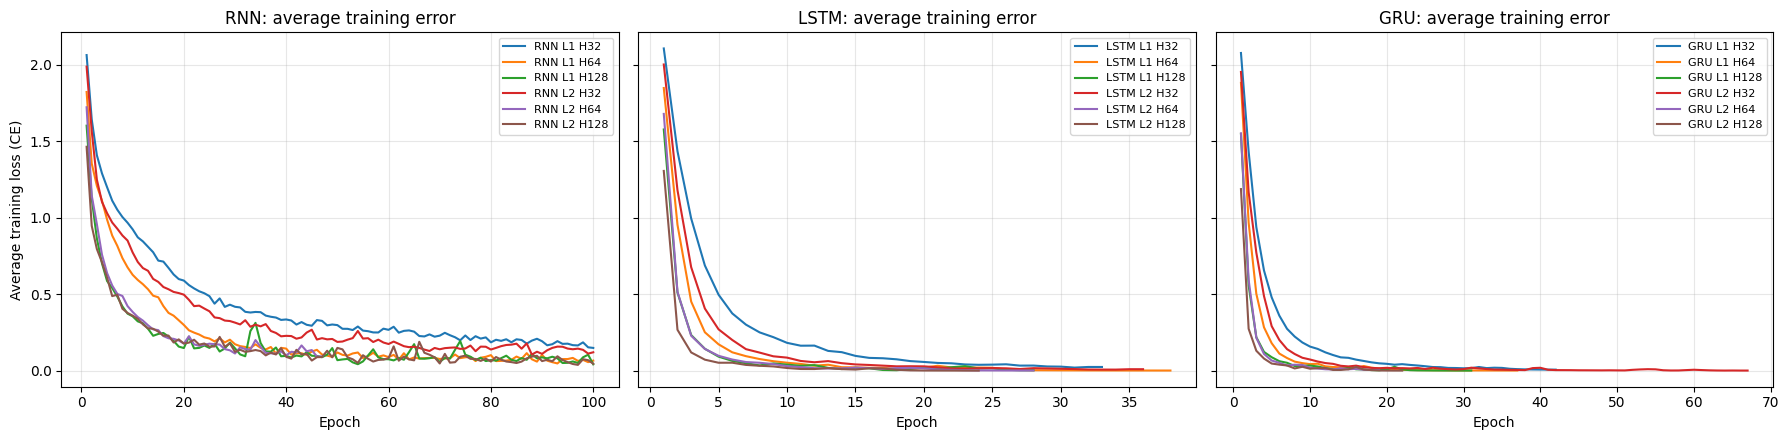

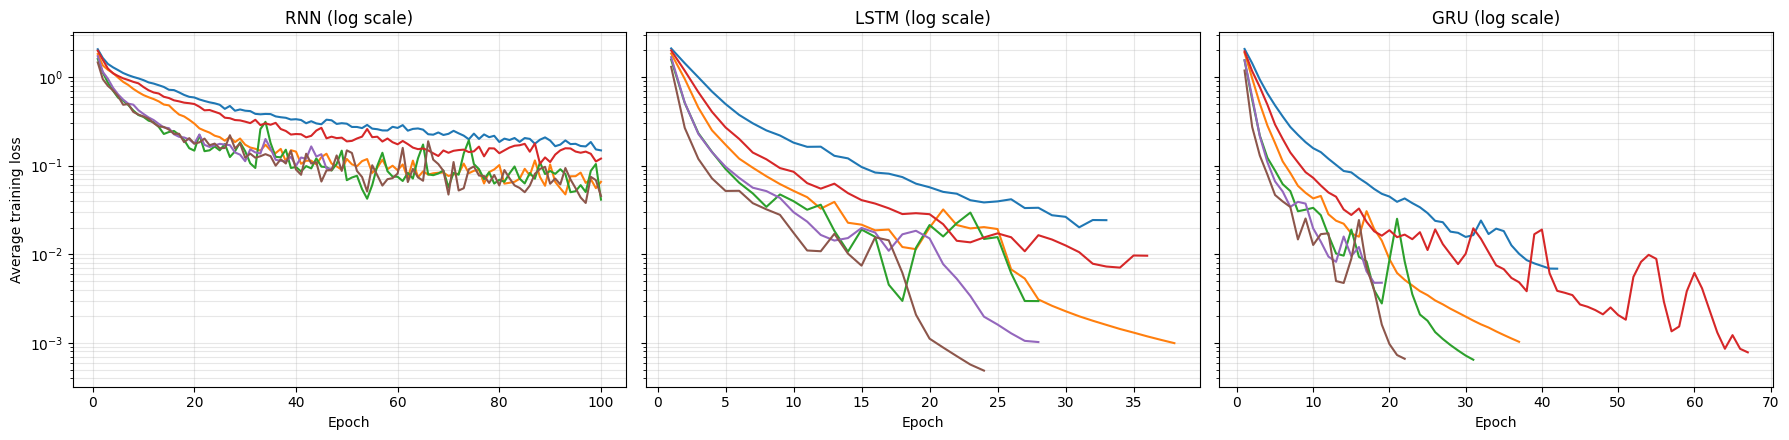

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, cell in zip(axes, CELLS):
    for r in [r for r in results if r["cfg"]["cell"] == cell]:
        ax.plot(range(1, r["epochs"] + 1), r["losses"], label=cfg_name(r["cfg"]))
    ax.set_title(f"{cell}: average training error"); ax.set_xlabel("Epoch")
    ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("Average training loss (CE)")
plt.tight_layout(); plt.savefig("task2_loss_curves.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, cell in zip(axes, CELLS):
    for r in [r for r in results if r["cfg"]["cell"] == cell]:
        ax.semilogy(range(1, r["epochs"] + 1), r["losses"], label=cfg_name(r["cfg"]))
    ax.set_title(f"{cell} (log scale)"); ax.set_xlabel("Epoch"); ax.grid(alpha=.3, which="both")
axes[0].set_ylabel("Average training loss")
plt.tight_layout(); plt.show()

In [9]:
def table(res):
    return pd.DataFrame([{
        "Model": cfg_name(r["cfg"]), "Cell": r["cfg"]["cell"], "Layers": r["cfg"]["layers"],
        "Hidden": r["cfg"]["hidden"], "BiDir": r["cfg"]["bidir"], "Attn": r["cfg"]["attn"],
        "Epochs": r["epochs"], "Converged": r["converged"], "Final loss": round(r["losses"][-1], 5),
        "Train acc (%)": round(100 * r["train_acc"], 2), "Val acc (%)": round(100 * r["val_acc"], 2),
        "Test acc (%)": round(100 * r["test_acc"], 2),
    } for r in res])

df = table(results)
df.to_csv("task2_summary_baseline.csv", index=False)
print(df.to_string(index=False))

print("\nMean accuracy per cell type:")
print(df.groupby("Cell")[["Train acc (%)", "Test acc (%)", "Epochs"]].mean().round(2))

       Model Cell  Layers  Hidden  BiDir  Attn  Epochs  Converged  Final loss  Train acc (%)  Val acc (%)  Test acc (%)
  RNN L1 H32  RNN       1      32  False False     100      False     0.14881          96.06        92.42         85.36
  RNN L1 H64  RNN       1      64  False False     100      False     0.06574          98.15        95.30         89.09
 RNN L1 H128  RNN       1     128  False False     100      False     0.04140          99.48        98.48         94.64
  RNN L2 H32  RNN       2      32  False False     100      False     0.12024          98.37        96.67         90.36
  RNN L2 H64  RNN       2      64  False False      47       True     0.09282          97.32        95.91         93.05
 RNN L2 H128  RNN       2     128  False False     100      False     0.04545          98.84        96.97         93.32
 LSTM L1 H32 LSTM       1      32  False False      33       True     0.02427          99.66        98.03         94.32
 LSTM L1 H64 LSTM       1      64  False

RNN L1 H128 Bi         epochs= 32 train=0.9961 val=0.9848 test=0.9645
RNN L1 H128 Attn       epochs= 60 train=1.0000 val=0.9909 test=0.9700
RNN L1 H128 Bi Attn    epochs= 40 train=1.0000 val=0.9939 test=0.9714
LSTM L2 H64 Bi         epochs= 16 train=1.0000 val=0.9939 test=0.9614
LSTM L2 H64 Attn       epochs= 37 train=1.0000 val=0.9939 test=0.9714
LSTM L2 H64 Bi Attn    epochs= 21 train=0.9987 val=0.9939 test=0.9636
GRU L2 H32 Bi          epochs= 29 train=1.0000 val=0.9970 test=0.9755
GRU L2 H32 Attn        epochs= 44 train=1.0000 val=0.9939 test=0.9695
GRU L2 H32 Bi Attn     epochs= 26 train=1.0000 val=0.9955 test=0.9800
              Model Cell  Layers  Hidden  BiDir  Attn  Epochs  Converged  Final loss  Train acc (%)  Val acc (%)  Test acc (%)
     RNN L1 H128 Bi  RNN       1     128   True False      32       True     0.02077          99.61        98.48         96.45
   RNN L1 H128 Attn  RNN       1     128  False  True      60       True     0.00070         100.00        99.09    

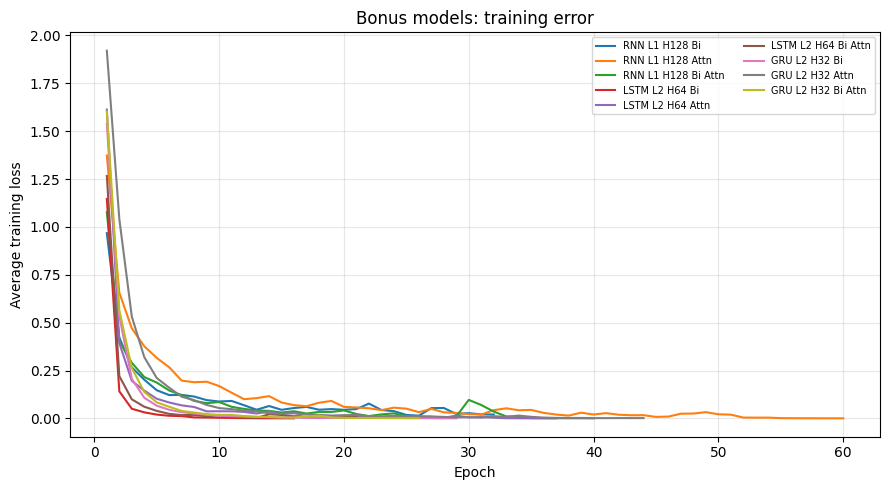

In [10]:
best_per_cell = {c: max([r for r in results if r["cfg"]["cell"] == c], key=lambda r: r["val_acc"])
                 for c in CELLS}
bonus = []
for c, b in best_per_cell.items():
    for bi, at in [(True, False), (False, True), (True, True)]:
        cfg = dict(b["cfg"]); cfg.update(bidir=bi, attn=at)
        r = train_model(cfg); bonus.append(r)
        print(f"{cfg_name(cfg):22s} epochs={r['epochs']:3d} train={r['train_acc']:.4f} "
              f"val={r['val_acc']:.4f} test={r['test_acc']:.4f}")

df_bonus = table(bonus)
df_bonus.to_csv("task2_summary_bonus.csv", index=False)
print(df_bonus.to_string(index=False))

plt.figure(figsize=(9, 5))
for r in bonus:
    plt.plot(range(1, r["epochs"] + 1), r["losses"], label=cfg_name(r["cfg"]))
plt.xlabel("Epoch"); plt.ylabel("Average training loss"); plt.title("Bonus models: training error")
plt.grid(alpha=.3); plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

===== Best standard model: GRU L2 H32 =====
Epochs to converge  : 67 (converged=True)
Final train accuracy: 100.00%
Validation accuracy : 99.55%
Test accuracy       : 96.27%
              precision    recall  f1-score   support

           0     0.9142    0.9682    0.9404       220
           1     0.9690    0.9955    0.9821       220
           2     0.9641    0.9773    0.9707       220
           3     0.9577    0.9273    0.9423       220
           4     0.9729    0.9773    0.9751       220
           5     0.9234    0.9864    0.9538       220
           6     0.9854    0.9182    0.9506       220
           7     0.9631    0.9500    0.9565       220
           8     0.9904    0.9364    0.9626       220
           9     0.9954    0.9909    0.9932       220

    accuracy                         0.9627      2200
   macro avg     0.9636    0.9627    0.9627      2200
weighted avg     0.9636    0.9627    0.9627      2200



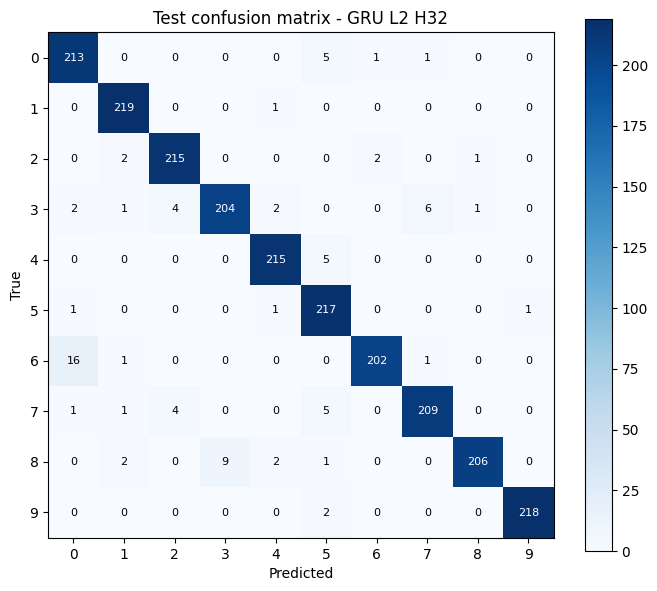

===== Best overall (incl. bonus): GRU L2 H32 Bi =====
Epochs to converge  : 29 (converged=True)
Final train accuracy: 100.00%
Validation accuracy : 99.70%
Test accuracy       : 97.55%
              precision    recall  f1-score   support

           0     0.9188    0.9773    0.9471       220
           1     0.9821    1.0000    0.9910       220
           2     0.9954    0.9864    0.9909       220
           3     0.9718    0.9409    0.9561       220
           4     0.9729    0.9773    0.9751       220
           5     0.9778    1.0000    0.9888       220
           6     1.0000    0.9409    0.9696       220
           7     0.9861    0.9682    0.9771       220
           8     0.9771    0.9682    0.9726       220
           9     0.9777    0.9955    0.9865       220

    accuracy                         0.9755      2200
   macro avg     0.9760    0.9755    0.9755      2200
weighted avg     0.9760    0.9755    0.9755      2200



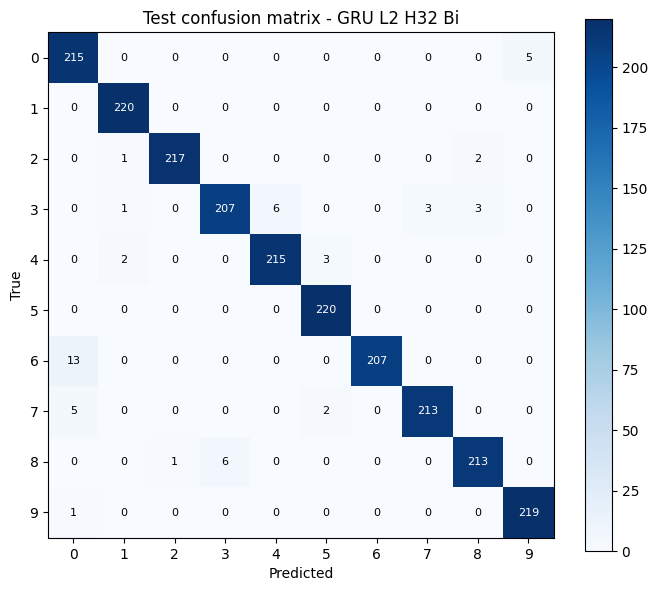

In [11]:
def plot_cm(cm, title, fname=None):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    fig.colorbar(im); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

def report(r, tag):
    print(f"===== {tag}: {cfg_name(r['cfg'])} =====")
    print(f"Epochs to converge  : {r['epochs']} (converged={r['converged']})")
    print(f"Final train accuracy: {100*r['train_acc']:.2f}%")
    print(f"Validation accuracy : {100*r['val_acc']:.2f}%")
    print(f"Test accuracy       : {100*r['test_acc']:.2f}%")
    _, p, t = evaluate(r["model"], test_loader)
    cm = confusion_matrix(t, p, labels=range(10))
    print(classification_report(t, p, digits=4))
    plot_cm(cm, f"Test confusion matrix - {cfg_name(r['cfg'])}",
            f"task2_cm_{tag.replace(' ', '_')}.png")
    return cm

best_base = max(results, key=lambda r: r["val_acc"])      # chosen by VALIDATION accuracy
cm_base = report(best_base, "Best standard model")

best_all = max(results + bonus, key=lambda r: r["val_acc"])
if best_all is not best_base:
    cm_all = report(best_all, "Best overall (incl. bonus)")

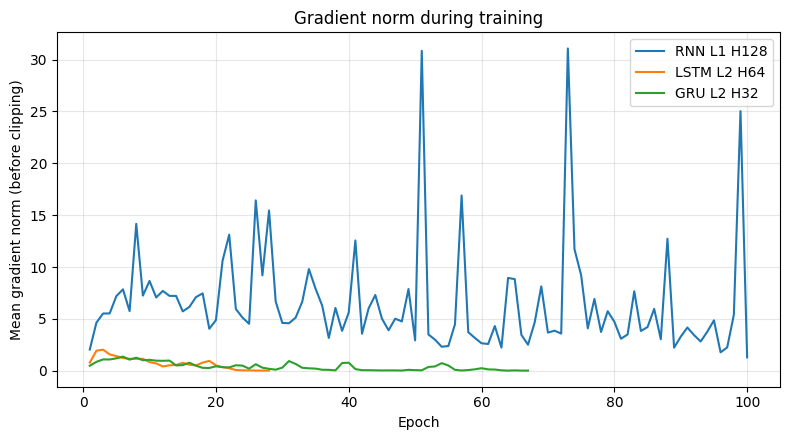

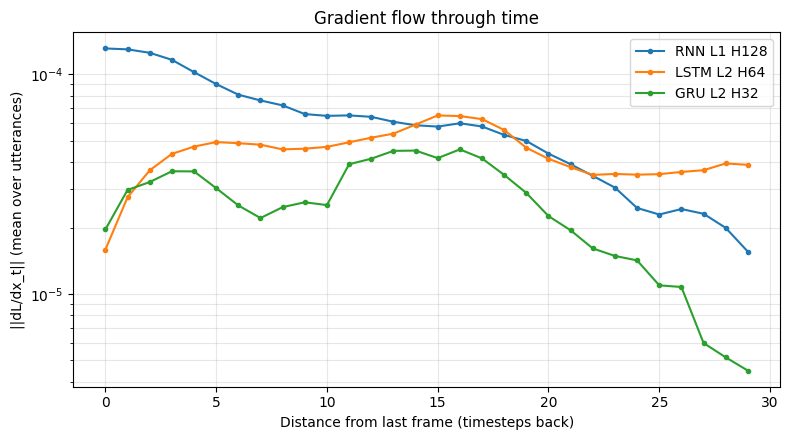

In [12]:
plt.figure(figsize=(8, 4.5))
for c in CELLS:
    r = best_per_cell[c]
    plt.plot(range(1, r["epochs"] + 1), r["gnorms"], label=cfg_name(r["cfg"]))
plt.xlabel("Epoch"); plt.ylabel("Mean gradient norm (before clipping)")
plt.title("Gradient norm during training"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig("task2_gradnorm_epochs.png", dpi=150); plt.show()

def grad_vs_distance(model, xs, ys, D=30, n=512):
    ids = [i for i, x in enumerate(xs) if len(x) >= D][:n]
    x = pad_sequence([xs[i] for i in ids], batch_first=True).to(DEVICE).requires_grad_(True)
    l = torch.tensor([len(xs[i]) for i in ids])
    y = torch.tensor([int(ys[i]) for i in ids]).to(DEVICE)
    old_do = model.rnn.dropout; model.rnn.dropout = 0.0       # no noise in the probe
    model.train()                                             # cuDNN RNN backward needs train mode
    nn.CrossEntropyLoss()(model(x, l), y).backward()
    model.rnn.dropout = old_do
    g = x.grad.norm(dim=2).cpu().numpy()
    out = np.zeros(D)
    for b, L in enumerate(l.numpy()):
        out += g[b, L - D:L][::-1]                            # index 0 = last frame
    return out / len(ids)

plt.figure(figsize=(8, 4.5))
for c in CELLS:
    r = best_per_cell[c]
    g = grad_vs_distance(r["model"], Xte_t, y_test)
    plt.semilogy(range(len(g)), g, marker="o", ms=3, label=cfg_name(r["cfg"]))
plt.xlabel("Distance from last frame (timesteps back)")
plt.ylabel("||dL/dx_t|| (mean over utterances)")
plt.title("Gradient flow through time"); plt.grid(alpha=.3, which="both"); plt.legend()
plt.tight_layout(); plt.savefig("task2_gradflow_time.png", dpi=150); plt.show()

# New Section

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [13]:
cmp = pd.DataFrame([{
    "Cell": c, "Best config": cfg_name(best_per_cell[c]["cfg"]),
    "Epochs": best_per_cell[c]["epochs"],
    "Train acc (%)": round(100 * best_per_cell[c]["train_acc"], 2),
    "Val acc (%)": round(100 * best_per_cell[c]["val_acc"], 2),
    "Test acc (%)": round(100 * best_per_cell[c]["test_acc"], 2),
    "Time (s)": round(best_per_cell[c]["time"], 1)} for c in CELLS])
print(cmp.to_string(index=False))

Cell Best config  Epochs  Train acc (%)  Val acc (%)  Test acc (%)  Time (s)
 RNN RNN L1 H128     100          99.48        98.48         94.64     301.5
LSTM LSTM L2 H64      28         100.00        99.39         95.41     358.5
 GRU  GRU L2 H32      67         100.00        99.55         96.27     454.0
